# Ablation — necessity / sufficiency numbers

Recomputes the numbers of the paper's hand-typed ablation tables (`Text/Appendix/ablation_necessity.tex`
sink table, `tables/sufficiency.tex`) from
`results/evaluation/ablation/<model>/{necessity,sufficiency}/<config>/summary.json`
(produced by `scripts/evaluation/eval_ablation_{necessity,sufficiency}.py`, shared machinery in
`scripts/evaluation/ablation_common.py`). Metric = oracle judge on the greedy-decoded frontier value:
*does the completion still implement the frontier description?*

- **Necessity** — attention-sink the goal heads (`ablated`, restricted to position 0), vs a matched
  random `control` from the later half of the LM.
- **Sufficiency** — spare *only* the goal heads and blind the rest (`ablated`), vs sparing a matched
  random set (`control`). If the goal heads carry the goal, `ablated`≈baseline while `control` collapses.

Canonical runs: `__ctrl=later_half` control (layers ≥ 32), 122- and 250-head goal sets, n=253.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, glob, re
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from rich import print as rich_print
from rich.table import Table

GROUP='ablation'
MODEL=F.model_slug()  # $GOALS_MODEL (an HF id or its slug), default Coder-32B
ABL=os.path.join(env_utils.DEFAULT_RESULTS_DIR,'evaluation','ablation',MODEL)

# ── condition palette: baseline / goal-ablated / random-control ──
# goal-ablated is the visually strongest (Okabe-Ito vermillion); baseline blue, control green.
COND_COLOR={'baseline':'#4C72B0', 'ablated':'#D55E00', 'control':'#009E73'}
COND_LABEL={'baseline':'baseline', 'ablated':'goal-ablated', 'control':'random-control'}
DATATYPES=['int','list[int]','list[str]','str']

def _leaf_parts(path):
    leaf=os.path.basename(os.path.dirname(path))
    return dict(re.findall(r'([a-zA-Z_]+)=([^_]+(?:\[[^\]]*\])?)', leaf)), leaf

def load(axis):
    """Return {(budget, strat): summary} for the canonical later_half / n=253 runs of an axis."""
    out={}
    for p in sorted(glob.glob(os.path.join(ABL,axis,'*','summary.json'))):
        leaf=os.path.basename(os.path.dirname(p))
        if '__ctrl=later_half' not in leaf: continue          # canonical control
        s=json.load(open(p))
        if s.get('n')!=253: continue                          # full corpus only
        m=re.search(r'goal(\d+)', leaf); strat=re.search(r'strat=(.+?)__dtype', leaf)
        if not (m and strat): continue
        out[(f'goal{m.group(1)}', strat.group(1))]=s
    return out

NEC=load('necessity')
SUF=load('sufficiency')
print('necessity runs:', sorted(NEC)); print('sufficiency runs:', sorted(SUF))

necessity runs: [('goal122', 'blind_task'), ('goal122', 'blind_task_and_progress'), ('goal122', 'sink'), ('goal250', 'blind_task'), ('goal250', 'blind_task_and_progress'), ('goal250', 'sink')]
sufficiency runs: [('goal122', 'blind_span'), ('goal250', 'blind_span')]


                  Necessity — frontier implement-rate (n=253)                   
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ strategy                ┃ budget  ┃ baseline ┃ goal-ablated ┃ random-control ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ blind_task              │ goal122 │    0.925 │        0.881 │          0.925 │
│ blind_task              │ goal250 │    0.925 │        0.806 │          0.925 │
│ blind_task_and_progress │ goal122 │    0.925 │        0.372 │          0.929 │
│ blind_task_and_progress │ goal250 │    0.925 │        0.249 │          0.925 │
│ sink                    │ goal122 │    0.925 │        0.854 │          0.925 │
│ sink                    │ goal250 │    0.925 │        0.158 │          0.925 │
└─────────────────────────┴─────────┴──────────┴──────────────┴────────────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ablation/necessity.tex


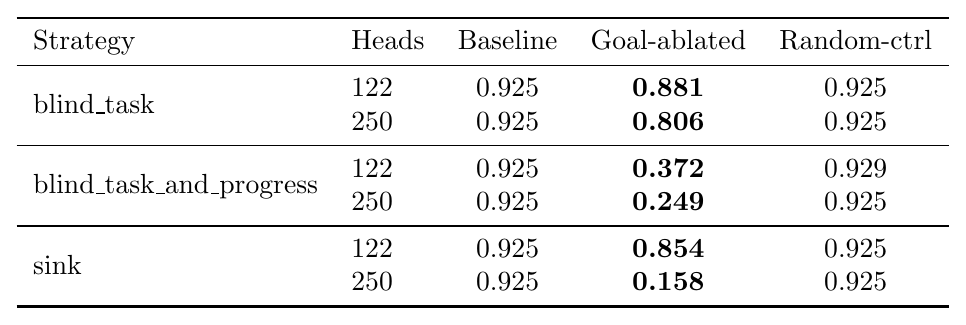

In [2]:
# ── Table: NECESSITY — implementation success (baseline / goal-ablated / random-control) ──
NEC_STRATS=[('sink','sink')]
# the two head sets' sizes (G-small, G-large): $GOALS_ABLATION_SETS, default Coder-32B's 122,250
BUDGETS=['goal'+k for k in os.environ.get('GOALS_ABLATION_SETS','122,250').split(',')]

t=Table(title='Necessity — frontier implement-rate (n=253)')
t.add_column('strategy'); t.add_column('budget')
for c in ['baseline','ablated','control']: t.add_column(COND_LABEL[c], justify='right')
for strat,_ in NEC_STRATS:
    for b in BUDGETS:
        o=NEC[(b,strat)]['overall']
        t.add_row(strat, b, f"{o['baseline']:.3f}", f"[bold red]{o['ablated']:.3f}[/bold red]", f"{o['control']:.3f}")
rich_print(t)

# LaTeX (booktabs): rows = strategy x budget, cols = baseline / goal-ablated / random-control
lines=[]
for strat,tex_s in NEC_STRATS:
    for i,b in enumerate(BUDGETS):
        o=NEC[(b,strat)]['overall']
        lead=('\\multirow{2}{*}{%s}'%tex_s) if i==0 else ''
        lines.append(f"{lead} & {b.replace('goal','')} & {o['baseline']:.3f} & \\textbf{{{o['ablated']:.3f}}} & {o['control']:.3f} \\\\")
    if strat!=NEC_STRATS[-1][0]: lines.append('\\midrule')
body='\n'.join(lines)
tex=('\\begin{tabular}{llccc}\n\\toprule\n'
     'Strategy & Heads & Baseline & Goal-ablated & Random-ctrl \\\\\n\\midrule\n'
     + body + '\n\\bottomrule\n\\end{tabular}')
path=F.save_table(tex, GROUP, 'necessity'); print('wrote', path)
img=F.render_latex_table(tex)
img if img is not None else rich_print('[dim](latex preview unavailable; see rich table above)[/dim]')

 Sufficiency — frontier implement-rate (n=253) 
┏━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ budget  ┃ clean ┃ spare-goal ┃ spare-random ┃
┡━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ goal122 │ 0.925 │      0.806 │        0.103 │
│ goal250 │ 0.925 │      0.913 │        0.087 │
└─────────┴───────┴────────────┴──────────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/ablation/sufficiency.tex


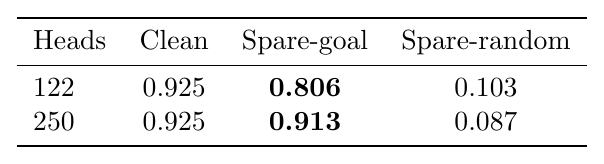

In [4]:
# ── Table: SUFFICIENCY — clean / spare-goal / spare-random (blind the rest) ──
SUF_LABEL={'baseline':'clean', 'ablated':'spare-goal', 'control':'spare-random'}
t=Table(title='Sufficiency — frontier implement-rate (n=253)')
t.add_column('budget')
for c in ['baseline','ablated','control']: t.add_column(SUF_LABEL[c], justify='right')
for b in BUDGETS:
    o=SUF[(b,'blind_span')]['overall']
    t.add_row(b, f"{o['baseline']:.3f}", f"[bold]{o['ablated']:.3f}[/bold]", f"[red]{o['control']:.3f}[/red]")
rich_print(t)

lines=[]
for b in BUDGETS:
    o=SUF[(b,'blind_span')]['overall']
    lines.append(f"{b.replace('goal','')} & {o['baseline']:.3f} & \\textbf{{{o['ablated']:.3f}}} & {o['control']:.3f} \\\\")
body='\n'.join(lines)
tex=('\\begin{tabular}{lccc}\n\\toprule\n'
     'Heads & Clean & Spare-goal & Spare-random \\\\\n\\midrule\n'
     + body + '\n\\bottomrule\n\\end{tabular}')
path=F.save_table(tex, GROUP, 'sufficiency'); print('wrote', path)
img=F.render_latex_table(tex)
img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')